In [ ]:
import pandas as pd
import numpy as np
import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from google.colab import drive
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [ ]:
try:
    drive.mount('/content/drive')
    DRIVE_MOUNTED = True
except:
    print("Google Drive tidak dapat di-mount. Pastikan menjalankan ini di Google Colab.")
    DRIVE_MOUNTED = False

path_en = '/content/drive/MyDrive/Digistar Class Intern 2025 by Telkom Indonesia/Project Telkom/Digistar Class/Hard Skill/sms_spam_collection/SMSSpamCollection.csv'
path_id = '/content/drive/MyDrive/Digistar Class Intern 2025 by Telkom Indonesia/Project Telkom/Digistar Class/Hard Skill/sms_spam_collection/SMSSpamCollectionIndo.csv'

In [ ]:
labels = []
texts = []

with open(path_en, 'r', encoding='latin-1') as file:
    for line in file:
        parts = line.strip().split('\t', 1)
        if len(parts) == 2:
            labels.append(parts[0])
            texts.append(parts[1].replace(';', ''))

df_en = pd.DataFrame({
    'label': labels,
    'text': texts
})

df_en['label'] = df_en['label'].str.replace('"', '', regex=False)

df_en['label'] = df_en['label'].map({'ham': 0, 'spam': 1})

print("Dataset Inggris berhasil dimuat:")
print(df_en['label'].value_counts())
print("-" * 30)

In [ ]:
df_id = pd.read_csv(path_id, sep=',', header=0, names=['text', 'label'])
print("Dataset Indonesia berhasil dimuat:")
print(df_id['label'].value_counts())
print("-" * 30)

In [ ]:
df = pd.concat([df_en, df_id], ignore_index=True)

df.dropna(subset=['label'], inplace=True)

print("Distribusi label setelah penggabungan:")
print(df['label'].value_counts())
print("-" * 30)

In [ ]:
def clean_text(text):
    """Fungsi untuk membersihkan teks: lowercase dan hapus karakter non-alphanumeric."""
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text

df['clean_text'] = df['text'].apply(clean_text)
y = df['label'].values
class_names = ['Normal (Bukan Spam)', 'Fraud/Spam/Hoax', 'Promo (Bukan Spam)']

In [ ]:
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df['clean_text'])

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_clf, y_train_clf)
y_pred_nb = nb.predict(X_test_clf)
print("=== Laporan Klasifikasi Naive Bayes ===")
print(classification_report(y_test_clf, y_pred_nb, target_names=class_names))

# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_clf, y_train_clf)
y_pred_lr = lr.predict(X_test_clf)
print("=== Laporan Klasifikasi Logistic Regression ===")
print(classification_report(y_test_clf, y_pred_lr, target_names=class_names))

# Support Vector Machine (SVM)
svm = LinearSVC(dual=True)
svm.fit(X_train_clf, y_train_clf)
y_pred_svm = svm.predict(X_test_clf)
print("=== Laporan Klasifikasi SVM ===")
print(classification_report(y_test_clf, y_pred_svm, target_names=class_names))

=== Laporan Klasifikasi Naive Bayes ===
                     precision    recall  f1-score   support

Normal (Bukan Spam)       0.94      1.00      0.97      1080
    Fraud/Spam/Hoax       0.94      0.72      0.82       220
 Promo (Bukan Spam)       0.94      0.71      0.81        48

           accuracy                           0.94      1348
          macro avg       0.94      0.81      0.87      1348
       weighted avg       0.94      0.94      0.94      1348

=== Laporan Klasifikasi Logistic Regression ===
                     precision    recall  f1-score   support

Normal (Bukan Spam)       0.94      1.00      0.97      1080
    Fraud/Spam/Hoax       0.98      0.77      0.86       220
 Promo (Bukan Spam)       0.94      0.60      0.73        48

           accuracy                           0.95      1348
          macro avg       0.95      0.79      0.86      1348
       weighted avg       0.95      0.95      0.94      1348

=== Laporan Klasifikasi SVM ===
                    

In [ ]:
VOCAB_SIZE = 10000
MAX_LEN = 120
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(df['clean_text'])
sequences = tokenizer.texts_to_sequences(df['clean_text'])

X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

In [ ]:
if DRIVE_MOUNTED:
    tokenizer_path = '/content/drive/MyDrive/Digistar Class Intern 2025 by Telkom Indonesia/Project Telkom/Digistar Class/Hard Skill/sms spam collection/multiclass_tokenizer.pkl'
    with open(tokenizer_path, 'wb') as f:
        pickle.dump(tokenizer, f)
    print(f"Tokenizer berhasil disimpan di: {tokenizer_path}")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, input_length=MAX_LEN),
    tf.keras.layers.Conv1D(filters=128, kernel_size=5, activation='relu'),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(3, activation='softmax')
])

In [ ]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=20,
                    validation_data=(X_test, y_test),
                    batch_size=32,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step

--- Laporan Klasifikasi CNN ---

                     precision    recall  f1-score   support

Normal (Bukan Spam)       0.99      0.99      0.99      1080
    Fraud/Spam/Hoax       0.94      0.93      0.93       220
 Promo (Bukan Spam)       0.84      0.85      0.85        48

           accuracy                           0.97      1348
          macro avg       0.92      0.92      0.92      1348
       weighted avg       0.97      0.97      0.97      1348



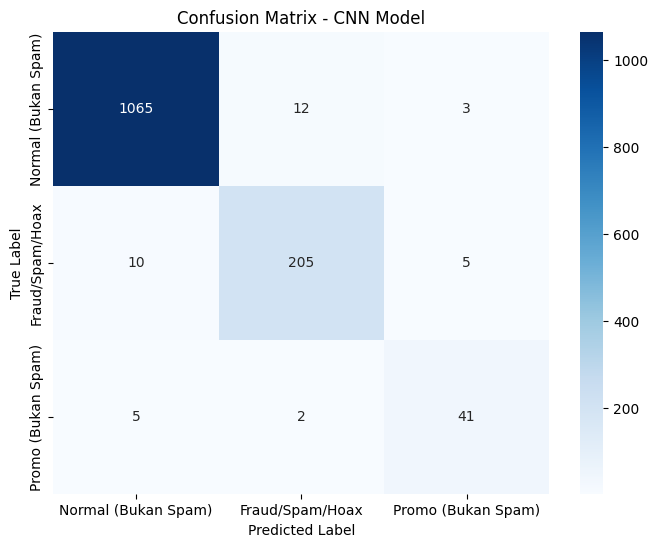

In [ ]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Laporan Klasifikasi CNN ---\n")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - CNN Model')
plt.show()

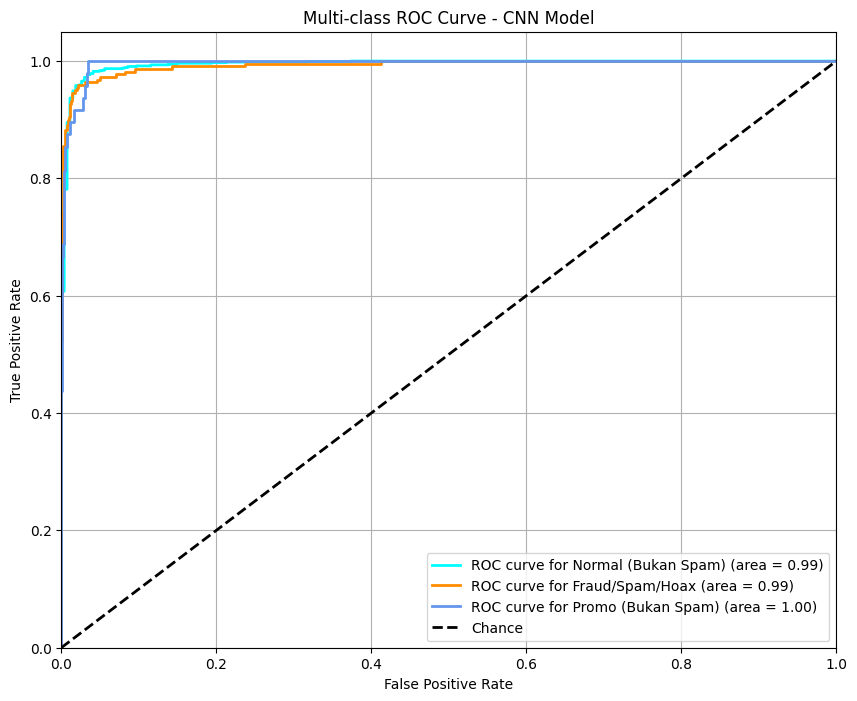

In [ ]:
y_test_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_binarized.shape[1]

fpr, tpr, roc_auc = dict(), dict(), dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
colors = ['aqua', 'darkorange', 'cornflowerblue']
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve for {class_names[i]} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve - CNN Model')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
if DRIVE_MOUNTED:
    model_path = '/content/drive/MyDrive/Digistar Class Intern 2025 by Telkom Indonesia/Project Telkom/Digistar Class/Hard Skill/sms spam collection/spam_multiclass_cnn_model.h5'
    model.save(model_path)
    print(f"Model berhasil disimpan di Google Drive: {model_path}")

In [ ]:
test_sms = [
    "Halo, Bapak/Ibu. Perkenalkan, saya Raka dari Tim Pelayanan Pelanggan PT Sinar Terang.",
    "BIG SALE HARI INI! Dapatkan Diskon 50% untuk semua produk elektronik hanya di Shopee! Promo hanya sampai jam 12 malam! segera transfer Rp1.050.000 ke rekening 888888888",
    "Selamat! Anda terpilih untuk bekerja di PT. Sukses Abadi sebagai Admin Gudang dengan gaji Rp8.500.000/bulan. Harap segera transfer Rp150.000 ke rekening 123-456-789 a.n."
]


In [ ]:
clean_sms = [clean_text(s) for s in test_sms]
seq_sms = tokenizer.texts_to_sequences(clean_sms)
pad_sms = pad_sequences(seq_sms, maxlen=MAX_LEN, padding='post', truncating='post')
predictions = model.predict(pad_sms)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


In [ ]:
for i, sms in enumerate(test_sms):
    pred_class_index = np.argmax(predictions[i])
    pred_label = class_names[pred_class_index]
    print(f"\nSMS: '{sms}'")
    print(f"Prediksi CNN: {pred_label}")
    print(f"Probabilitas: {predictions[i]}")


SMS: 'Halo, Bapak/Ibu. Perkenalkan, saya Raka dari Tim Pelayanan Pelanggan PT Sinar Terang.'
Prediksi CNN: Normal (Bukan Spam)
Probabilitas: [0.77455574 0.08881839 0.13662587]

SMS: 'BIG SALE HARI INI! Dapatkan Diskon 50% untuk semua produk elektronik hanya di Shopee! Promo hanya sampai jam 12 malam! segera transfer Rp1.050.000 ke rekening 888888888'
Prediksi CNN: Promo (Bukan Spam)
Probabilitas: [0.01475571 0.46719396 0.5180503 ]

SMS: 'Selamat! Anda terpilih untuk bekerja di PT. Sukses Abadi sebagai Admin Gudang dengan gaji Rp8.500.000/bulan. Harap segera transfer Rp150.000 ke rekening 123-456-789 a.n.'
Prediksi CNN: Fraud/Spam/Hoax
Probabilitas: [0.08354095 0.57925355 0.33720547]
